# Predicting paediatric appendicitis: diagnosis, severity and treatment

**Data:** Regensburg Pediatric Appendicitis dataset (UCI id 938): 782 children admitted with abdominal pain to Children's Hospital St. Hedwig, Regensburg, 2016 to 2021. Each child has lab results, clinical examination findings, clinical scores and ultrasound findings.

**Question:** from information available at admission, can we predict three things?

1. **Diagnosis:** appendicitis or not
2. **Severity:** complicated (gangrenous, perforated or abscessed) or not
3. **Management:** surgery or conservative treatment

**Approach:** five models per outcome, compared with the clinical scores doctors already use, using stratified 5-fold cross-validation repeated 3 times.

This is a rebuilt version of my MSc module project (Machine Learning and Pattern Recognition, Dublin Business School). The section at the end lists what changed and why.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
SEED = 42

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": MUTED,
    "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

## 1. Load the data

The first run downloads the data from the UCI repository with `ucimlrepo` and saves a local copy in `data/`. The data is licensed CC BY-NC 4.0, so the CSV is not included in this repository.

In [2]:
raw = data.load_raw(ROOT / "data" / "appendicitis.csv")
targets = data.make_targets(raw)
X, numeric_cols, categorical_cols = data.feature_table(raw)

print(f"Patients: {len(raw)}")
print(f"Model inputs: {X.shape[1]} ({len(numeric_cols)} numeric, {len(categorical_cols)} categorical)")
print("\nLeft out of the model inputs:")
for col, reason in data.EXCLUDED.items():
    print(f"  {col}: {reason}")
print("\nOutcome balance (share of 1s):")
print(targets.mean().round(3).rename({"Diagnosis": "Diagnosis (appendicitis)", "Severity": "Severity (complicated)", "Management": "Management (surgery)"}).to_string())

Patients: 782
Model inputs: 52 (16 numeric, 36 categorical)

Left out of the model inputs:
  Diagnosis_Presumptive: the doctor's suspected diagnosis, close to the answer itself
  Length_of_Stay: only known after treatment (surgical patients stay longer)
  US_Number: an ultrasound image ID, not a clinical measurement

Outcome balance (share of 1s):
Diagnosis (appendicitis)    0.594
Severity (complicated)      0.152
Management (surgery)        0.382


### A note on the diagnosis label

For children who had surgery, the diagnosis was confirmed by histology. For children treated without surgery, the dataset authors labelled them as having appendicitis if their Alvarado or Paediatric Appendicitis Score was at least 4 **and** their appendix diameter was at least 6 mm.

That rule uses three of the model's own inputs, so for about 60% of patients the diagnosis label is partly built from the features. The check below confirms it, which means diagnosis scores here will look better than they would on truly independent labels.

In [3]:
rule = (((raw["Alvarado_Score"] >= 4) | (raw["Paedriatic_Appendicitis_Score"] >= 4)) & (raw["Appendix_Diameter"] >= 6)).astype(int)
conservative = raw["Management"] == "conservative"
known = targets["Diagnosis"].notna()
share = accuracy_score(targets.loc[known & conservative, "Diagnosis"], rule[known & conservative])
print(f"Conservatively treated patients whose diagnosis matches the labelling rule: {share:.1%}")

Conservatively treated patients whose diagnosis matches the labelling rule: 99.4%


### How much data is missing?

Many ultrasound findings are only recorded when something was seen, so they are mostly empty. For categorical columns, "missing" is kept as its own category, because the absence of a finding carries information. Numeric gaps are filled with the training-fold median.

In [4]:
missing = (X.isna().mean() * 100).sort_values(ascending=False)
print(f"Columns more than 50% empty: {(missing > 50).sum()} of {len(missing)}")
missing.head(10).round(0)

Columns more than 50% empty: 18 of 52


Abscess_Location               98.0
Gynecological_Findings         97.0
Conglomerate_of_Bowel_Loops    95.0
Segmented_Neutrophils          93.0
Ileus                          92.0
Perfusion                      92.0
Enteritis                      92.0
Appendicolith                  91.0
Coprostasis                    91.0
Perforation                    90.0
dtype: float64

## 2. Models

| Model | Inputs |
|---|---|
| Clinical scores only (logistic regression) | Alvarado and Paediatric Appendicitis Scores |
| Logistic regression | All inputs |
| Random forest | All inputs |
| XGBoost | All inputs |
| Neural network (one hidden layer, scikit-learn MLP) | All inputs |

Every model sits in a scikit-learn pipeline, so imputation, scaling and encoding are fitted on the training folds only. The classes are imbalanced (especially severity), so logistic regression, random forest and XGBoost use class weights. Settings are fixed rather than tuned, to keep the comparison simple.

In [5]:
def preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                              OneHotEncoder(handle_unknown="ignore")), cat_cols),
    ])


def build_models(pos_weight):
    full = lambda: preprocessor(numeric_cols, categorical_cols)
    return {
        "Clinical scores only": (data.CLINICAL_SCORES, Pipeline([
            ("prep", preprocessor(data.CLINICAL_SCORES, [])),
            ("model", LogisticRegression(class_weight="balanced", max_iter=1000))])),
        "Logistic regression": (list(X.columns), Pipeline([
            ("prep", full()), ("model", LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000))])),
        "Random forest": (list(X.columns), Pipeline([
            ("prep", full()), ("model", RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                class_weight="balanced_subsample", random_state=SEED, n_jobs=-1))])),
        "XGBoost": (list(X.columns), Pipeline([
            ("prep", full()), ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8, scale_pos_weight=pos_weight,
                eval_metric="logloss", random_state=SEED, n_jobs=-1))])),
        "Neural network": (list(X.columns), Pipeline([
            ("prep", full()), ("model", MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-3,
                early_stopping=True, max_iter=500, random_state=SEED))])),
    }

## 3. Cross-validated results

Stratified 5-fold cross-validation, repeated 3 times (15 fits per model). ROC AUC is the main measure because it does not depend on a decision threshold. Balanced accuracy and recall (the share of positive cases caught) are reported at the default threshold of 0.5.

In [6]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
scoring = {"AUC": "roc_auc", "Balanced accuracy": "balanced_accuracy", "Accuracy": "accuracy", "Recall": "recall"}

rows = []
for target in data.TARGETS:
    known = targets[target].notna()
    y = targets.loc[known, target].astype(int)
    pos_weight = (1 - y.mean()) / y.mean()
    for name, (cols, pipe) in build_models(pos_weight).items():
        scores = cross_validate(pipe, X.loc[known, cols], y, cv=cv, scoring=scoring)
        row = {"Outcome": target, "Model": name}
        for metric in scoring:
            row[metric] = scores[f"test_{metric}"].mean()
        row["AUC sd"] = scores["test_AUC"].std()
        rows.append(row)

results = pd.DataFrame(rows)
results.to_csv(FIGURES / "results.csv", index=False)
results.style.format({c: "{:.3f}" for c in ["AUC", "AUC sd", "Balanced accuracy", "Accuracy", "Recall"]}).hide(axis="index")

Outcome,Model,AUC,Balanced accuracy,Accuracy,Recall,AUC sd
Diagnosis,Clinical scores only,0.728,0.666,0.676,0.719,0.029
Diagnosis,Logistic regression,0.966,0.913,0.907,0.882,0.014
Diagnosis,Random forest,0.968,0.914,0.913,0.909,0.012
Diagnosis,XGBoost,0.982,0.950,0.949,0.943,0.010
Diagnosis,Neural network,0.938,0.862,0.863,0.868,0.023
Severity,Clinical scores only,0.722,0.655,0.655,0.655,0.034
Severity,Logistic regression,0.905,0.815,0.862,0.748,0.028
Severity,Random forest,0.918,0.795,0.879,0.675,0.026
Severity,XGBoost,0.902,0.762,0.871,0.606,0.028
Severity,Neural network,0.884,0.630,0.867,0.288,0.047


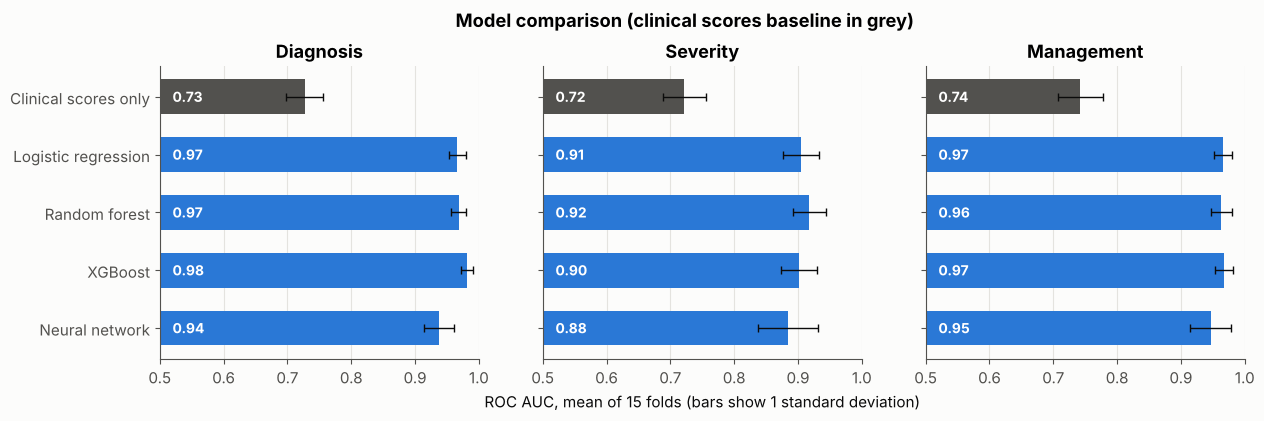

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
order = list(build_models(1).keys())[::-1]
for ax, target in zip(axes, data.TARGETS):
    sub = results[results["Outcome"] == target].set_index("Model").loc[order]
    colors = [MUTED if name == "Clinical scores only" else BLUE for name in sub.index]
    ax.barh(sub.index, sub["AUC"], xerr=sub["AUC sd"], color=colors, height=0.6,
            error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 3})
    for y_pos, v in enumerate(sub["AUC"]):
        ax.text(0.52, y_pos, f"{v:.2f}", va="center", color="white", fontsize=10, fontweight="bold")
    ax.set_xlim(0.5, 1.0)
    ax.set_title(target)
    ax.grid(axis="y", visible=False)
    if ax is not axes[0]:
        ax.set_yticklabels([])
axes[1].set_xlabel("ROC AUC, mean of 15 folds (bars show 1 standard deviation)")
fig.suptitle("Model comparison (clinical scores baseline in grey)", fontweight="bold", y=1.03)
fig.savefig(FIGURES / "auc_by_model.png")
plt.show()

### What the numbers say

- **Every model beats the clinical scores alone by a wide margin.** The Alvarado and Paediatric Appendicitis Scores reach an AUC of about 0.72 to 0.74. Adding lab and ultrasound findings lifts that to around 0.9 or more.
- **Diagnosis and treatment are the easiest to predict.** The best models reach an AUC of 0.97 to 0.98. For diagnosis, part of this comes from the labelling rule described above.
- **Severity is the hardest.** Complicated cases are only 15% of patients. At the default threshold, the class-weighted models catch 61% to 75% of them. The neural network, which has no class weights, catches only 29%.
- **Simple models hold their own.** Logistic regression is within 0.02 AUC of the best model on every outcome. The neural network is the weakest of the full models, which is common on small tabular datasets.

## 4. ROC curves and confusion matrices (XGBoost)

Out-of-fold predictions from a single 5-fold split, so every patient is predicted by a model that never saw them.

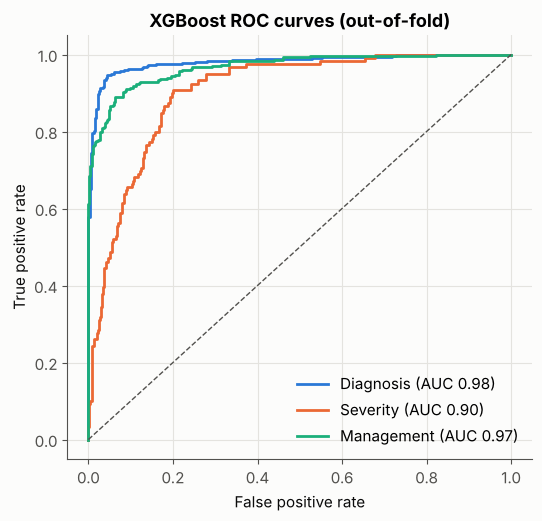

In [8]:
oof = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for target in data.TARGETS:
    known = targets[target].notna()
    y = targets.loc[known, target].astype(int)
    _, pipe = build_models((1 - y.mean()) / y.mean())["XGBoost"]
    prob = cross_val_predict(pipe, X.loc[known], y, cv=skf, method="predict_proba")[:, 1]
    oof[target] = (y.to_numpy(), prob)

fig, ax = plt.subplots(figsize=(6, 5.5))
for target, color in zip(data.TARGETS, [BLUE, ORANGE, AQUA]):
    y, prob = oof[target]
    fpr, tpr, _ = roc_curve(y, prob)
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{target} (AUC {roc_auc_score(y, prob):.2f})")
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("XGBoost ROC curves (out-of-fold)")
ax.legend(frameon=False, loc="lower right")
fig.savefig(FIGURES / "roc_curves.png")
plt.show()

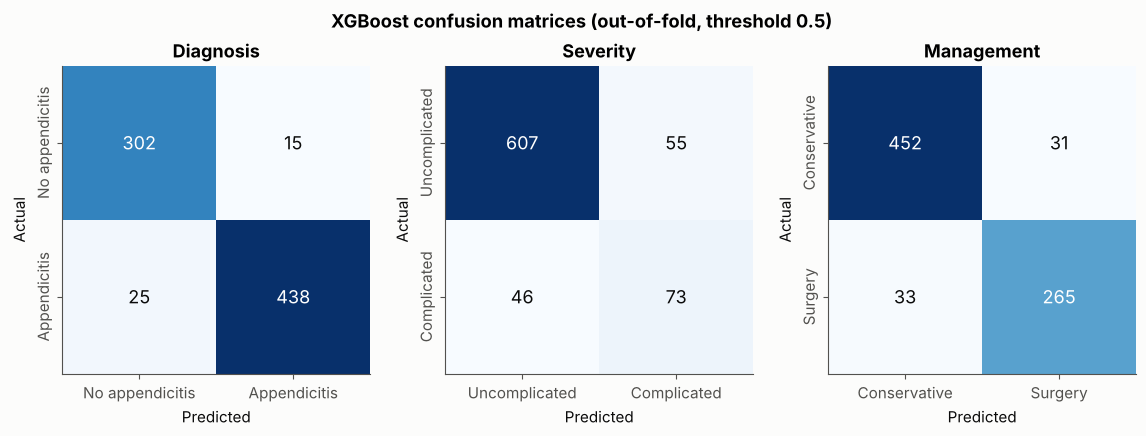

In [9]:
labels = {
    "Diagnosis": ["No appendicitis", "Appendicitis"],
    "Severity": ["Uncomplicated", "Complicated"],
    "Management": ["Conservative", "Surgery"],
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, target in zip(axes, data.TARGETS):
    y, prob = oof[target]
    cm = confusion_matrix(y, (prob >= 0.5).astype(int))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=13,
                color="white" if v > cm.max() / 2 else INK)
    ax.set_xticks([0, 1], labels[target])
    ax.set_yticks([0, 1], labels[target], rotation=90, va="center")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(target)
    ax.grid(False)
fig.suptitle("XGBoost confusion matrices (out-of-fold, threshold 0.5)", fontweight="bold", y=1.02)
fig.savefig(FIGURES / "confusion_matrices.png")
plt.show()

## 5. Which features matter? (SHAP)

XGBoost is refitted on all patients for each outcome, and SHAP values are summed back from the one-hot columns to the original features.

One caution: for categorical findings, "missing" is its own category. A finding is often only recorded when a child was examined more closely, so part of a feature's importance can reflect how patients were documented rather than the finding itself.

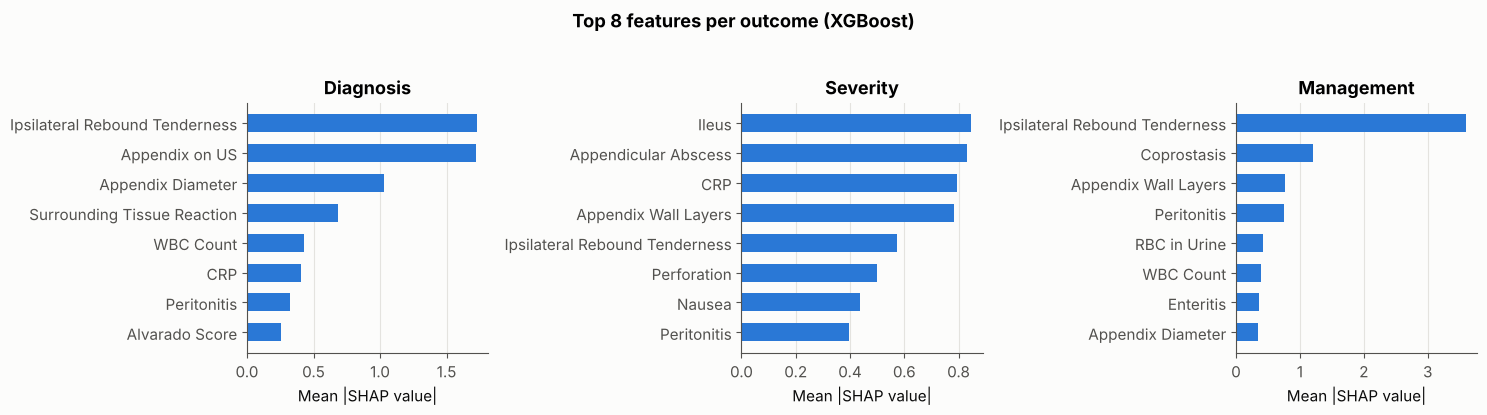

Diagnosis: Ipsilateral Rebound Tenderness, Appendix on US, Appendix Diameter, Surrounding Tissue Reaction
Severity: Ileus, Appendicular Abscess, CRP, Appendix Wall Layers
Management: Ipsilateral Rebound Tenderness, Coprostasis, Appendix Wall Layers, Peritonitis


In [10]:
pretty = lambda name: name.replace("_", " ").replace("Paedriatic", "Paediatric")

top_features = {}
for target in data.TARGETS:
    known = targets[target].notna()
    y = targets.loc[known, target].astype(int)
    _, pipe = build_models((1 - y.mean()) / y.mean())["XGBoost"]
    pipe.fit(X.loc[known], y)
    Xt = pipe.named_steps["prep"].transform(X.loc[known])
    Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
    values = shap.TreeExplainer(pipe.named_steps["model"]).shap_values(Xt)
    names = pipe.named_steps["prep"].get_feature_names_out()
    original = [n.split("__", 1)[1] for n in names]
    original = [next((c for c in categorical_cols if o.startswith(c + "_")), o) for o in original]
    top_features[target] = (pd.Series(np.abs(values).mean(axis=0), index=original)
                            .groupby(level=0).sum().sort_values(ascending=False).head(8))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, target in zip(axes, data.TARGETS):
    imp = top_features[target][::-1]
    ax.barh([pretty(i) for i in imp.index], imp.values, color=BLUE, height=0.6)
    ax.set_title(target)
    ax.set_xlabel("Mean |SHAP value|")
    ax.grid(axis="y", visible=False)
fig.suptitle("Top 8 features per outcome (XGBoost)", fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIGURES / "shap_top_features.png")
plt.show()

for target in data.TARGETS:
    print(f"{target}: {', '.join(pretty(f) for f in top_features[target].index[:4])}")

## 6. Why length of stay was removed

The original version of this project used length of hospital stay as an input. It was the single most important feature, but it is only known after treatment, so a model that relies on it cannot be used at admission. The check below shows its effect on the treatment model.

In [11]:
known = targets["Management"].notna()
y = targets.loc[known, "Management"].astype(int)
X_with_stay = X.loc[known].assign(Length_of_Stay=raw.loc[known, "Length_of_Stay"])
numeric_with_stay = numeric_cols + ["Length_of_Stay"]

with_stay = Pipeline([
    ("prep", preprocessor(numeric_with_stay, categorical_cols)),
    ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, eval_metric="logloss", random_state=SEED, n_jobs=-1)),
]).fit(X_with_stay, y)
names = with_stay.named_steps["prep"].get_feature_names_out()
importance = pd.Series(with_stay.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
print("Top features when length of stay is included:")
print(importance.head(3).round(3).to_string())
print("\nMedian length of stay (days):")
print(raw.groupby("Management")["Length_of_Stay"].median().to_string())

Top features when length of stay is included:
num__Length_of_Stay                       0.140
cat__Ipsilateral_Rebound_Tenderness_no    0.068
cat__Peritonitis_no                       0.062

Median length of stay (days):
Management
conservative                 3.0
primary surgical             6.0
secondary surgical           4.0
simultaneous appendectomy    4.0


## 7. What changed from the original module project

| Original notebook | This version | Why |
|---|---|---|
| Target was the first target column, which is **management** (treatment), while the report called it diagnosis | All three outcomes modelled and named correctly | The model must answer the question the report describes |
| Management had three classes, one with only 5 test patients | Surgery vs conservative, as defined by the dataset authors | The tiny third class could not be learned or evaluated reliably |
| Length of stay used as an input | Removed, along with the suspected diagnosis and an ultrasound image ID | Not available at admission |
| Imputer, encoders and scaler fitted on all data before the split | Fitted inside each pipeline on training folds only | Keeps test data out of training |
| One unstratified 80/20 split | Stratified 5-fold cross-validation, repeated 3 times | More reliable scores with small data |
| Accuracy only | ROC AUC, balanced accuracy and recall | Accuracy hides poor performance on rare classes |
| No baseline | Clinical scores (Alvarado and PAS) | Shows what the models add over current practice |
| "CNN": a 1D convolution on tabular data with a yes/no output for a 3-class target | Simple neural network (MLP) | The original set-up could not produce valid results |
| UMAP plot | Removed | It was not used by any model |

## 8. Limitations

- **Diagnosis labels are partly rule-based** for conservatively treated patients, which inflates diagnosis scores.
- **Documentation patterns.** Whether a finding was recorded at all can carry signal, so some feature importance reflects how patients were examined.
- **One hospital, 782 patients.** Results may not carry over to other hospitals.
- **No external test set or threshold tuning.** In practice, a hospital would choose a threshold that catches nearly all complicated cases, at the cost of more false alarms.
- **Not a medical tool.** This is a learning project and must not be used for clinical decisions.